In [1]:
import numpy as np 
import gold_codes as gc

from matplotlib import pyplot as plt

In [2]:
import importlib
importlib.reload(gc)

<module 'gold_codes' from '/Users/heller/Documents/binary_sequences/gold_codes/gold_codes.py'>

In [3]:
bits_per_symbol = 32

m = gc.gold_codec(14, bits_per_symbol)
m.shape

(32, 16383)

In [4]:
msg = np.frombuffer(b"abcdefghijklmnop", dtype=np.uint8)

rng = np.random.default_rng()
msg = rng.integers(255, size=1<<16, dtype=np.uint8)
print(msg.shape, msg.dtype)
tx_bits = np.unpackbits(msg).reshape(-1, bits_per_symbol)
tx_bits.shape, tx_bits.dtype, tx_bits

(65536,) uint8


((16384, 32),
 dtype('uint8'),
 array([[1, 0, 1, ..., 1, 1, 0],
        [1, 0, 1, ..., 1, 1, 0],
        [1, 1, 0, ..., 1, 0, 1],
        ...,
        [0, 1, 0, ..., 1, 0, 1],
        [0, 0, 0, ..., 1, 0, 1],
        [1, 0, 1, ..., 1, 1, 1]], dtype=uint8))

In [5]:
tx_bipolar = tx_bits.astype(np.float32) * 2 - 1
x = tx_bipolar @ m

x -= np.mean(x)
print(np.std(x))
x /= np.std(x)  # normalize tx power to 1

x.size/msg.size, x.shape, m.shape, np.mean(x), np.std(x), np.var(x)

5.6568584


(4095.75, (16384, 16383), (32, 16383), 6.9590538e-09, 0.99999714, 0.99999434)

In [6]:
snr = -14 # dB
noise = rng.normal(loc=0, scale=1/(10**(snr/20)), size=x.shape)
print(10*np.log10(np.var(x) / np.var(noise)))
y = x + noise

rx_hat = y @ m.T


rx_bits = rx_hat > 0

if False:
    print(rx_hat)
    print(rx_bits)
    rx_bits == tx_bits

np.mean(np.packbits(rx_bits) == msg)


-14.000381039295366


0.9999847412109375

(16383,) (16383,) 1.0


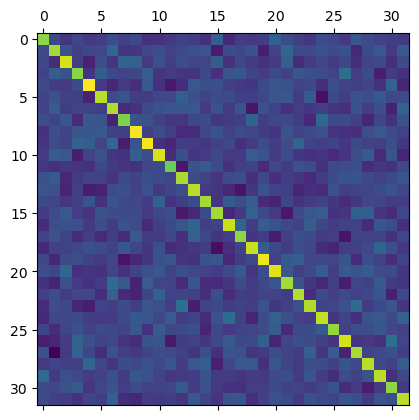

In [44]:
print(y[0].shape, m[0].shape, np.std(m[0]))

plt.matshow(m @ ((m.T) + rng.normal(loc=0, scale=1/(10**(-20/20)), size=m.T.shape)))

[ 0  1  2  3  4  5  6  7  8 27 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]


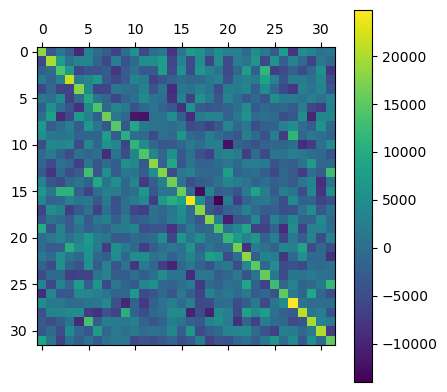

In [57]:
# random sequences are quasi-orthogonal, but not necessarity complementary
mm=rng.choice([-1, 1], m.shape)

z = mm @ ((mm.T) + rng.normal(loc=0, scale=1/(10**(-30/20)), size=mm.T.shape))
print(np.argmax(z, axis=1))
plt.matshow(z)
plt.colorbar()

In [8]:
import pickle 
if False:
    with open("../data/t5-parameters.pkl", "rb") as f:
        p = pickle.load(f)
    with open("../data/t5-parameters-10.pkl", "wb") as f:
        pickle.dump(p[:10], f)
else:
    with open("../data/t5-parameters-10.pkl", "rb") as f:
        p = pickle.load(f)

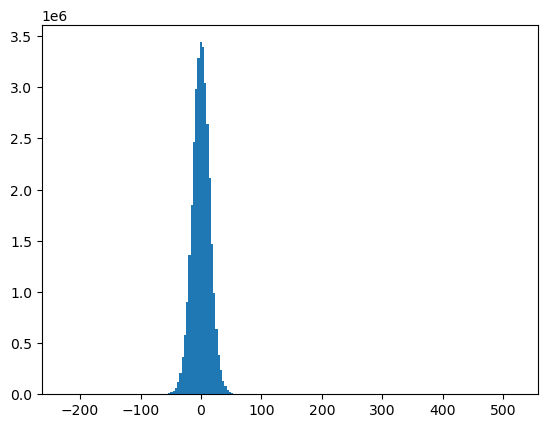

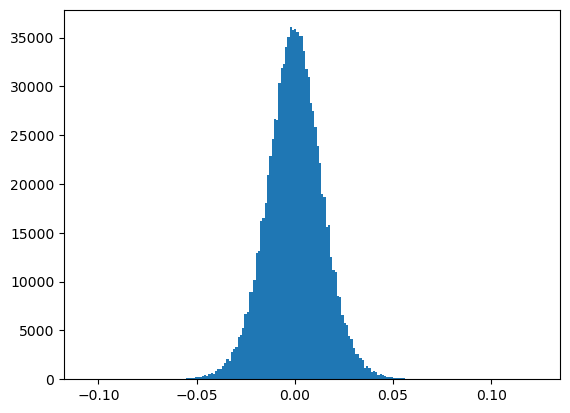

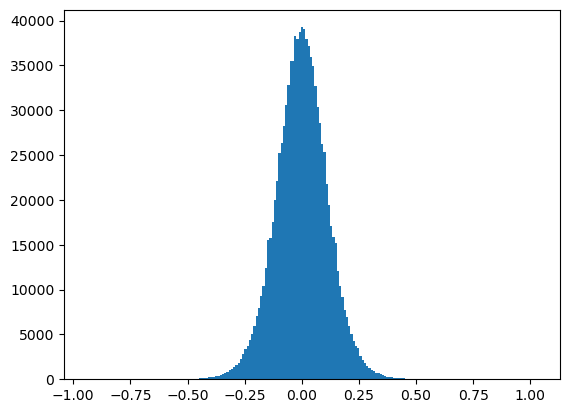

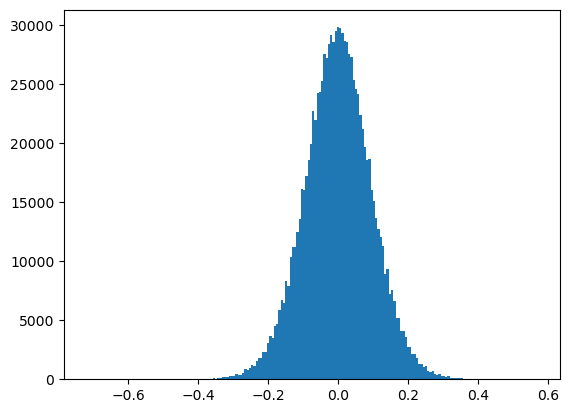

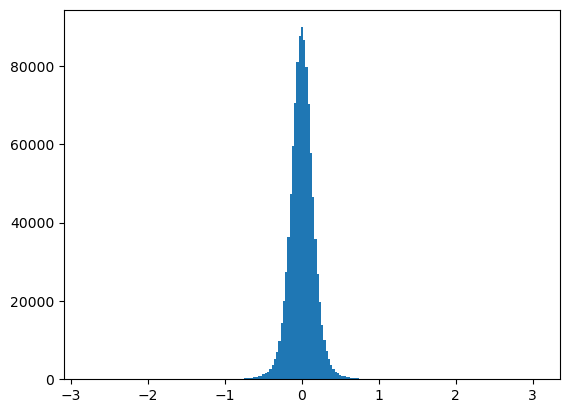

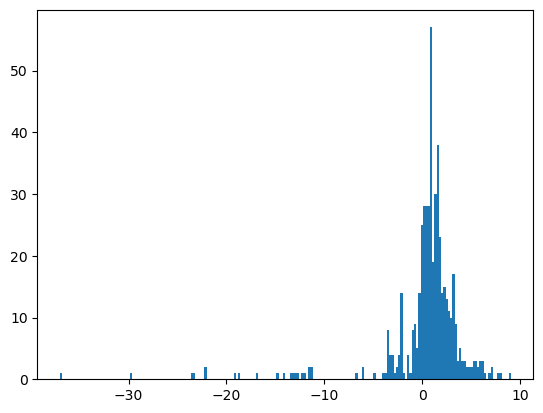

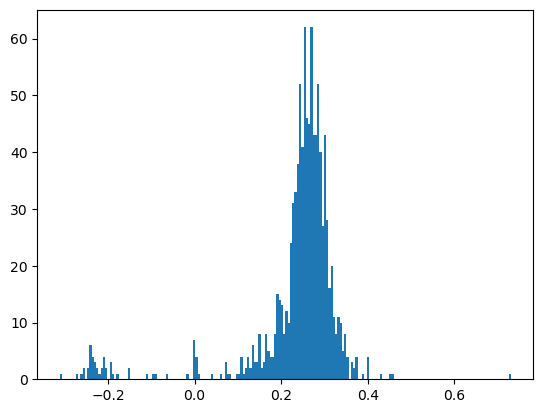

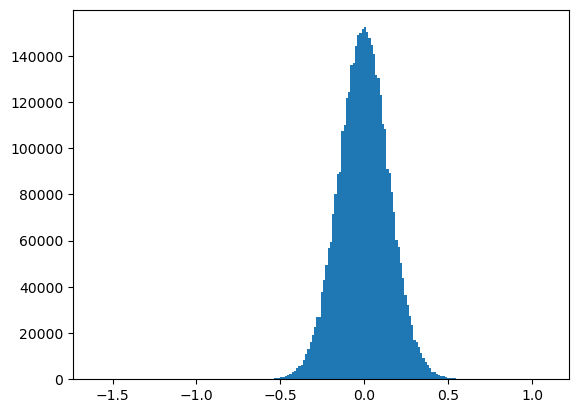

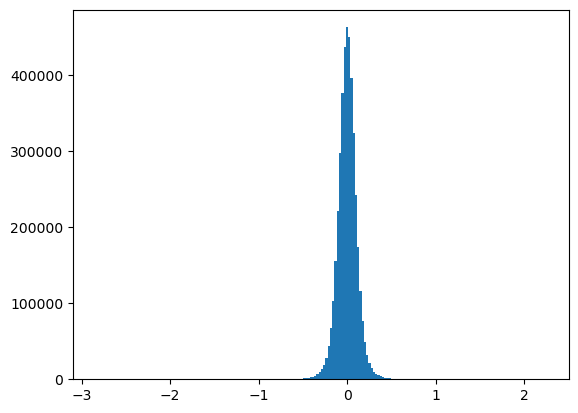

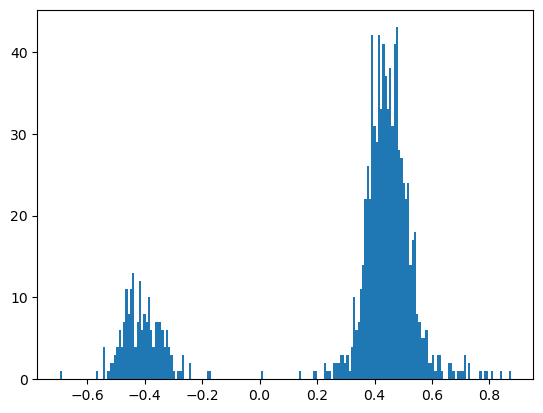

In [9]:
for pi in p:
    plt.hist(pi.ravel(), 200)
    plt.show()

In [10]:
rngs = [np.random.default_rng(0) for i in range(6)]

SyntaxError: invalid syntax (2379013799.py, line 1)